# EfficientDet Drone Detection Training

Complete notebook for training EfficientDet on your custom drone dataset.

## Dataset Format
- Images: JPG files in train/val folders
- Labels: YOLO format (class_id x_center y_center width height - normalized)
- Class: 0 = drone


In [ ]:
## 1. Install Required Packages


In [1]:
# Install required packages
%pip install -q torch torchvision torchaudio
%pip install -q albumentations pycocotools opencv-python pillow matplotlib tqdm

# Install EfficientDet
try:
    import effdet
    print("✓ effdet already installed")
except ImportError:
    print("Installing effdet...")
    %pip install -q effdet timm
    print("✓ Installed effdet and timm")


Installing effdet...
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 112.5/112.5 kB 4.5 MB/s eta 0:00:00
✓ Installed effdet and timm


In [ ]:
# Verify GPU is available
import torch
print(f"CUDA available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"Device: {torch.cuda.get_device_name(0)}")
    print(f"GPU Memory: {torch.cuda.get_device_properties(0).total_memory / 1024**3:.2f} GB")
else:
    print("WARNING: Running on CPU. Go to Runtime -> Change runtime type -> Hardware accelerator -> GPU")


CUDA available: True
Device: Tesla T4
GPU Memory: 14.74 GB


## 2. Mount Google Drive

We need access to your Drive to get the dataset and save the results.


In [2]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


## 3. Prepare Data

Copying data from Drive to the local Colab VM (`/content`) is much faster for training than reading directly from Drive.

**Option 1:** If your dataset is already in Drive as a folder, we'll copy it.
**Option 2:** If your dataset is zipped, we'll unzip it.


In [3]:
import os
import shutil
from pathlib import Path

# Define paths (Change these if your drive structure is different)
drive_project_path = '/content/drive/MyDrive/yolov8_project'  # Update this to your Drive folder
dataset_zip_path = f'{drive_project_path}/dataset.zip'
dataset_folder_path = f'{drive_project_path}/drone_dataset_split'  # If dataset is a folder
dataset_root = '/content/drone_dataset'

# Option 1: If dataset is zipped
if os.path.exists(dataset_zip_path):
    print("Found dataset zip file.")
    if os.path.exists(dataset_root):
        shutil.rmtree(dataset_root)
    os.makedirs(dataset_root, exist_ok=True)
    print("Unzipping...")
    !unzip -q "{dataset_zip_path}" -d "{dataset_root}"
    print("Unzip complete.")

    # Find the actual data folder
    base_path = Path(dataset_root)
    found_images = list(base_path.rglob('images'))
    if found_images:
        dataset_root = str(found_images[0].parent)
        print(f"Data root located at: {dataset_root}")

# Option 2: If dataset is a folder in Drive
elif os.path.exists(dataset_folder_path):
    print("Found dataset folder in Drive.")
    if os.path.exists(dataset_root):
        shutil.rmtree(dataset_root)
    shutil.copytree(dataset_folder_path, dataset_root)
    print(f"Copied dataset to: {dataset_root}")

else:
    print(f"Error: Could not find dataset.")
    print(f"Please make sure your dataset is at:")
    print(f"  - {dataset_zip_path} (zipped), OR")
    print(f"  - {dataset_folder_path} (folder)")
    print(f"\nUpdate 'drive_project_path' above if your dataset is in a different location.")


Found dataset zip file.
Unzipping...
Unzip complete.
Data root located at: /content/drone_dataset/drone_dataset_split


## 4. Import Libraries and Setup

Now we'll import all the necessary libraries for training.


In [4]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from effdet import EfficientDet
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm
from pathlib import Path
import albumentations as A

# Set device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using device: {device}')


Using device: cpu


## 5. Configuration

Configure your dataset paths and training parameters here. Adjust these values based on your needs.


In [5]:
# ========== CONFIGURATION ==========
# Dataset paths (automatically set from data preparation above)
IMAGES_DIR = "images"
LABELS_DIR = "labels"

# Training parameters
BATCH_SIZE = 8          # Reduce to 4 or 2 if you get out-of-memory errors
NUM_EPOCHS = 50         # Number of training epochs
LEARNING_RATE = 0.0001  # Learning rate
NUM_CLASSES = 1         # Only drone class (0 = drone)
MODEL_SCALE = 0         # EfficientDet-D0 (0-7, where 0 is smallest/fastest, 7 is largest/most accurate)
IMAGE_SIZE = 512        # Input image size (512, 640, or 768)

# Build paths
TRAIN_IMAGES = os.path.join(dataset_root, IMAGES_DIR, "train")
TRAIN_LABELS = os.path.join(dataset_root, LABELS_DIR, "train")
VAL_IMAGES = os.path.join(dataset_root, IMAGES_DIR, "val")
VAL_LABELS = os.path.join(dataset_root, LABELS_DIR, "val")

# Verify paths exist
print("Configuration loaded!")
print(f"Dataset root: {dataset_root}")
print(f"Train images: {TRAIN_IMAGES} - {'✓' if os.path.exists(TRAIN_IMAGES) else '✗ NOT FOUND'}")
print(f"Val images: {VAL_IMAGES} - {'✓' if os.path.exists(VAL_IMAGES) else '✗ NOT FOUND'}")
print(f"\nTraining settings:")
print(f"  Model: EfficientDet-D{MODEL_SCALE}")
print(f"  Batch size: {BATCH_SIZE}")
print(f"  Image size: {IMAGE_SIZE}x{IMAGE_SIZE}")
print(f"  Epochs: {NUM_EPOCHS}")
print(f"  Learning rate: {LEARNING_RATE}")


Configuration loaded!
Dataset root: /content/drone_dataset/drone_dataset_split
Train images: /content/drone_dataset/drone_dataset_split/images/train - ✓
Val images: /content/drone_dataset/drone_dataset_split/images/val - ✓

Training settings:
  Model: EfficientDet-D0
  Batch size: 8
  Image size: 512x512
  Epochs: 50
  Learning rate: 0.0001


## 6. Create Dataset Class

This custom dataset class loads your images and YOLO format labels, converting them to the format EfficientDet needs.


In [6]:
class DroneDataset(Dataset):
    """Dataset class for YOLO format drone detection"""

    def __init__(self, images_dir, labels_dir, image_size=512, transform=None, is_train=True):
        self.images_dir = images_dir
        self.labels_dir = labels_dir
        self.image_size = image_size
        self.transform = transform
        self.is_train = is_train

        # Get all image files
        self.image_files = [f for f in os.listdir(images_dir) if f.lower().endswith(('.jpg', '.jpeg', '.png'))]
        self.image_files.sort()

        print(f"Found {len(self.image_files)} images in {images_dir}")

    def __len__(self):
        return len(self.image_files)

    def __getitem__(self, idx):
        img_name = self.image_files[idx]
        img_path = os.path.join(self.images_dir, img_name)

        # Load image
        image = cv2.imread(img_path)
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        # Resize image
        image = cv2.resize(image, (self.image_size, self.image_size))

        # Load labels (YOLO format: class x_center y_center width height - normalized)
        label_name = os.path.splitext(img_name)[0] + '.txt'
        label_path = os.path.join(self.labels_dir, label_name)

        boxes = []
        labels = []

        if os.path.exists(label_path):
            with open(label_path, 'r') as f:
                for line in f.readlines():
                    parts = line.strip().split()
                    if len(parts) == 5:
                        class_id = int(parts[0])
                        x_center, y_center, width, height = map(float, parts[1:5])

                        # Convert YOLO format to Pascal VOC format (x_min, y_min, x_max, y_max)
                        # Multiply by image_size to get absolute pixel values
                        x_min = (x_center - width / 2) * self.image_size
                        y_min = (y_center - height / 2) * self.image_size
                        x_max = (x_center + width / 2) * self.image_size
                        y_max = (y_center + height / 2) * self.image_size

                        # CRITICAL: Strict clipping to [0, image_size] for Albumentations
                        x_min = max(0.0, min(x_min, float(self.image_size)))
                        y_min = max(0.0, min(y_min, float(self.image_size)))
                        x_max = max(0.0, min(x_max, float(self.image_size)))
                        y_max = max(0.0, min(y_max, float(self.image_size)))

                        # Only add if the box has actual area
                        if (x_max > x_min) and (y_max > y_min):
                            boxes.append([x_min, y_min, x_max, y_max])
                            labels.append(class_id)

        # Convert to numpy arrays
        boxes = np.array(boxes, dtype=np.float32) if len(boxes) > 0 else np.zeros((0, 4), dtype=np.float32)
        labels = np.array(labels, dtype=np.int64) if len(labels) > 0 else np.zeros((0,), dtype=np.int64)

        # Apply augmentations (Albumentations uses [xmin, ymin, xmax, ymax])
        if self.transform:
            transformed = self.transform(image=image, bboxes=boxes, class_labels=labels)
            image = transformed['image']
            if len(transformed['bboxes']) > 0:
                boxes = np.array(transformed['bboxes'], dtype=np.float32)
                labels = np.array(transformed['class_labels'], dtype=np.int64)
            else:
                boxes = np.zeros((0, 4), dtype=np.float32)
                labels = np.zeros((0,), dtype=np.int64)

        # Convert image to tensor
        if isinstance(image, np.ndarray):
            image = torch.from_numpy(image).permute(2, 0, 1).float()
            # ONLY divide by 255 if the transform didn't already do it
            if image.max() > 1.0:
                image = image / 255.0

        # IMPORTANT: EffDet expects [ymin, xmin, ymax, xmax]
        # We must reorder our Pascal VOC boxes [xmin, ymin, xmax, ymax]
        effdet_boxes = boxes.copy()
        if len(effdet_boxes) > 0:
            effdet_boxes = effdet_boxes[:, [1, 0, 3, 2]]

        target = {
            'boxes': torch.as_tensor(effdet_boxes, dtype=torch.float32),
            'labels': torch.as_tensor(labels, dtype=torch.int64) + 1, # +1 for background
            'image_id': torch.tensor([idx]),
            # Area is same regardless of [x,y] order
            'area': torch.as_tensor([(b[2]-b[0])*(b[3]-b[1]) for b in boxes], dtype=torch.float32),
            'iscrowd': torch.zeros((len(boxes),), dtype=torch.int64)
        }

        return image, target

## 7. Setup Data Augmentation and DataLoaders

Data augmentation helps improve model performance by creating variations of your training images. We'll create the training and validation datasets.


In [7]:
# Define augmentations (applied only to training data)
train_transform = A.Compose([
    A.HorizontalFlip(p=0.5),              # Randomly flip images horizontally
    A.RandomBrightnessContrast(p=0.2),   # Randomly adjust brightness/contrast
    A.RandomGamma(p=0.2),                # Randomly adjust gamma
    A.Blur(blur_limit=3, p=0.1),        # Randomly blur images
    A.MedianBlur(blur_limit=3, p=0.1),  # Randomly apply median blur
    A.ToFloat(),                         # Convert to float
], bbox_params=A.BboxParams(format='pascal_voc', label_fields=['class_labels']))

# No augmentation for validation
val_transform = A.Compose([
    A.ToFloat(),
], bbox_params=A.BboxParams(format='pascal_voc', label_fields=['class_labels']))

# Create datasets
print("Creating datasets...")
train_dataset = DroneDataset(
    images_dir=TRAIN_IMAGES,
    labels_dir=TRAIN_LABELS,
    image_size=IMAGE_SIZE,
    transform=train_transform,
    is_train=True
)

val_dataset = DroneDataset(
    images_dir=VAL_IMAGES,
    labels_dir=VAL_LABELS,
    image_size=IMAGE_SIZE,
    transform=val_transform,
    is_train=False
)

# Create data loaders
def collate_fn(batch):
    """Custom collate function to handle variable-sized batches"""
    images = [item[0] for item in batch]
    targets = [item[1] for item in batch]
    return images, targets

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    collate_fn=collate_fn,
    pin_memory=True if torch.cuda.is_available() else False
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    collate_fn=collate_fn,
    pin_memory=True if torch.cuda.is_available() else False
)

print(f"\nData loaders created:")
print(f"  Train batches: {len(train_loader)}")
print(f"  Val batches: {len(val_loader)}")


Creating datasets...
Found 951 images in /content/drone_dataset/drone_dataset_split/images/train
Found 203 images in /content/drone_dataset/drone_dataset_split/images/val

Data loaders created:
  Train batches: 119
  Val batches: 26


/usr/local/lib/python3.12/dist-packages/albumentations/core/composition.py:331: UserWarning: Got processor for bboxes, but no transform to process it.
  self._set_keys()


## 8. Initialize Model

Now we'll create the EfficientDet model. EfficientDet-D0 is the smallest and fastest, perfect for getting started.


In [8]:
from effdet import create_model

# Initialize EfficientDet model
print(f"Initializing EfficientDet-D{MODEL_SCALE}...")

# CORRECT WAY: Use create_model to automatically handle W_bifpn, D_bifpn, etc.
model = create_model(
    f'tf_efficientdet_d{MODEL_SCALE}',
    pretrained=True,
    num_classes=NUM_CLASSES,  # No need for +1 here, effdet handles it based on config
    image_size=(IMAGE_SIZE, IMAGE_SIZE) # Must be a tuple
)

model = model.to(device)

# Count parameters
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f"Model created successfully!")
print(f"  Total parameters: {total_params:,}")
print(f"  Trainable parameters: {trainable_params:,}")
print(f"  Model size: ~{total_params * 4 / 1024**2:.2f} MB (float32)")


Initializing EfficientDet-D0...
Downloading: "https://github.com/rwightman/efficientdet-pytorch/releases/download/v0.1/tf_efficientdet_d0_34-f153e0cf.pth" to /root/.cache/torch/hub/checkpoints/tf_efficientdet_d0_34-f153e0cf.pth
Model created successfully!
  Total parameters: 3,828,002
  Trainable parameters: 3,828,002
  Model size: ~14.60 MB (float32)


## 9. Setup Training

Configure the optimizer and learning rate scheduler for training.


In [9]:
# Optimizer (AdamW is a good default choice)
optimizer = optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=0.0001)

# Learning rate scheduler (gradually decreases learning rate)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=NUM_EPOCHS, eta_min=1e-6)

print("Training setup complete!")
print(f"  Optimizer: AdamW")
print(f"  Initial learning rate: {LEARNING_RATE}")
print(f"  Scheduler: CosineAnnealingLR")


Training setup complete!
  Optimizer: AdamW
  Initial learning rate: 0.0001
  Scheduler: CosineAnnealingLR


## 10. Train Model

This is where the magic happens! The model will learn to detect drones in your images. Training may take a while depending on your dataset size and number of epochs.

**Note:** The best model (lowest validation loss) will be saved automatically during training.


In [11]:
from effdet import DetBenchTrain

# 1. WRAP MODEL for Training
bench = DetBenchTrain(model)
bench = bench.to(device)

# Training history
train_losses = []
val_losses = []
best_val_loss = float('inf')
save_dir = '/content/checkpoints'
os.makedirs(save_dir, exist_ok=True)

print("=" * 60)
print("Starting training...")
print(f"Training for {NUM_EPOCHS} epochs")
print(f"Device: {device}")
print(f"Model: EfficientDet-D{MODEL_SCALE}")
print("=" * 60)

Starting training...
Training for 50 epochs
Device: cpu
Model: EfficientDet-D0


In [ ]:


for epoch in range(NUM_EPOCHS):
    # Training phase
    bench.train()
    train_loss = 0.0
    train_bar = tqdm(train_loader, desc=f'Epoch {epoch+1}/{NUM_EPOCHS} [Train]')

    for images, targets in train_bar:
        # 2. STACK IMAGES
        images = torch.stack(images).to(device)

        # 3. CORRECT TARGET FORMATTING
        batch_targets = {
            'bbox': [t['boxes'].to(device) for t in targets],
            'cls': [t['labels'].to(device) for t in targets],
            'img_size': torch.tensor([(IMAGE_SIZE, IMAGE_SIZE)] * len(targets), device=device).float(),
            'img_scale': torch.ones(len(targets), device=device).float()
        }

        optimizer.zero_grad()

        # Forward pass through the bench wrapper
        loss_dict = bench(images, batch_targets)
        loss = sum(loss for loss in loss_dict.values())

        # Backward pass
        loss.backward()
        optimizer.step()

        train_loss += loss.item()
        train_bar.set_postfix({'loss': f'{loss.item():.4f}'})

    avg_train_loss = train_loss / len(train_loader)
    train_losses.append(avg_train_loss)

    # Validation phase
    # CRITICAL FIX: Keep bench in .train() mode to calculate validation loss
    bench.train()
    val_loss = 0.0
    val_bar = tqdm(val_loader, desc=f'Epoch {epoch+1}/{NUM_EPOCHS} [Val]')

    # Use torch.no_grad() to prevent updating weights during validation
    with torch.no_grad():
        for images, targets in val_bar:
            images = torch.stack(images).to(device)

            # Use the same dictionary format for validation
            batch_targets = {
                'bbox': [t['boxes'].to(device) for t in targets],
                'cls': [t['labels'].to(device) for t in targets],
                'img_size': torch.tensor([(IMAGE_SIZE, IMAGE_SIZE)] * len(targets), device=device).float(),
                'img_scale': torch.ones(len(targets), device=device).float()
            }

            loss_dict = bench(images, batch_targets)
            loss = sum(loss for loss in loss_dict.values())

            val_loss += loss.item()
            val_bar.set_postfix({'loss': f'{loss.item():.4f}'})

    avg_val_loss = val_loss / len(val_loader)
    val_losses.append(avg_val_loss)

    # Update learning rate
    scheduler.step()

    # Save best model
    if avg_val_loss < best_val_loss:
        best_val_loss = avg_val_loss
        torch.save({
            'epoch': epoch + 1,
            'model_state_dict': bench.model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'val_loss': avg_val_loss,
        }, os.path.join(save_dir, 'best_model.pth'))
        print(f"\n✓ Saved best model (val_loss: {avg_val_loss:.4f})")

    print(f"\nEpoch {epoch+1}/{NUM_EPOCHS} Summary:")
    print(f"   Train Loss: {avg_train_loss:.4f}")
    print(f"   Val Loss: {avg_val_loss:.4f}")
    print(f"   Learning Rate: {scheduler.get_last_lr()[0]:.6f}")
    print("-" * 60)

print("\n" + "=" * 60)
print("Training completed!")
print(f"Best validation loss: {best_val_loss:.4f}")
print("=" * 60)

Starting training...
Training for 50 epochs
Device: cuda
Model: EfficientDet-D0


Epoch 1/50 [Val]: 100%|██████████| 26/26 [00:05<00:00,  4.50it/s, loss=1.6686]



✓ Saved best model (val_loss: 1.0602)

Epoch 1/50 Summary:
   Train Loss: 1.0961
   Val Loss: 1.0602
   Learning Rate: 0.000100
------------------------------------------------------------


Epoch 2/50 [Val]: 100%|██████████| 26/26 [00:04<00:00,  5.55it/s, loss=1.6940]



✓ Saved best model (val_loss: 0.9263)

Epoch 2/50 Summary:
   Train Loss: 0.7545
   Val Loss: 0.9263
   Learning Rate: 0.000100
------------------------------------------------------------


...


Epoch 48/50 Summary:
   Train Loss: 0.1330
   Val Loss: 0.8153
   Learning Rate: 0.000001
------------------------------------------------------------


Epoch 49/50 [Val]: 100%|██████████| 26/26 [00:05<00:00,  4.65it/s, loss=1.1600]



Epoch 49/50 Summary:
   Train Loss: 0.1330
   Val Loss: 0.8036
   Learning Rate: 0.000001
------------------------------------------------------------


Epoch 50/50 [Val]: 100%|██████████| 26/26 [00:05<00:00,  4.53it/s, loss=1.2524]


Epoch 50/50 Summary:
   Train Loss: 0.1340
   Val Loss: 0.8263
   Learning Rate: 0.000001
------------------------------------------------------------

Training completed!
Best validation loss: 0.7077


## 11. View Training History

Let's visualize how the training progressed over time.


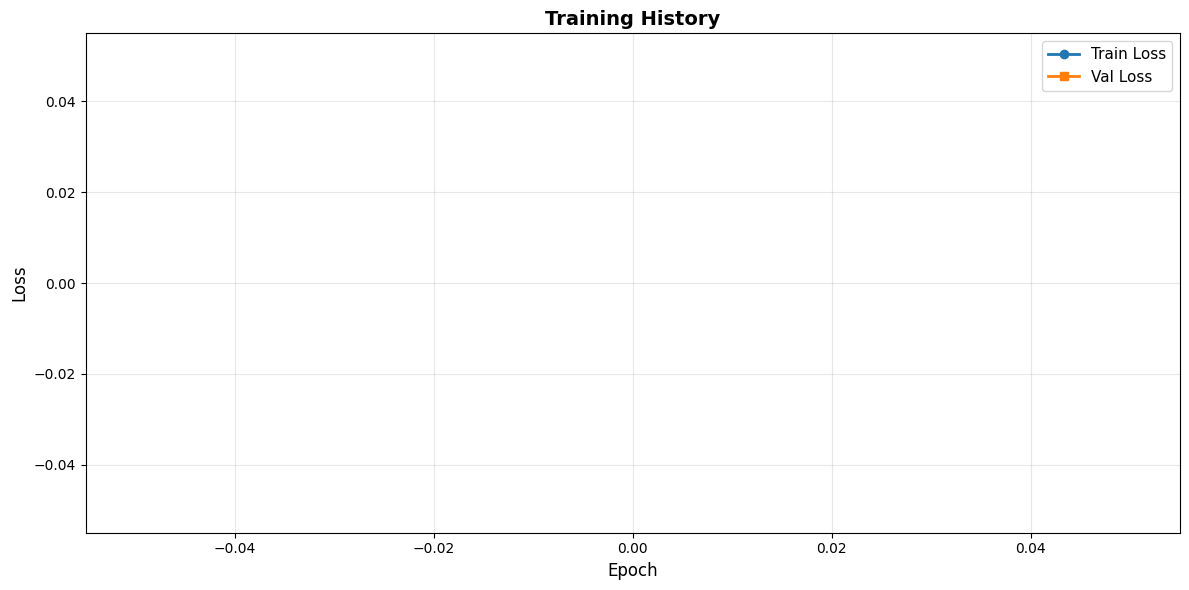

Best validation loss: inf


IndexError: list index out of range

In [12]:
# Plot training history
plt.figure(figsize=(12, 6))
plt.plot(train_losses, label='Train Loss', marker='o', linewidth=2)
plt.plot(val_losses, label='Val Loss', marker='s', linewidth=2)
plt.xlabel('Epoch', fontsize=12)
plt.ylabel('Loss', fontsize=12)
plt.title('Training History', fontsize=14, fontweight='bold')
plt.legend(fontsize=11)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Best validation loss: {best_val_loss:.4f}")
print(f"Final train loss: {train_losses[-1]:.4f}")
print(f"Final val loss: {val_losses[-1]:.4f}")


reloading our weight without retraining

In [15]:
# 1. Define the device (automatically detects if GPU is available or not)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Current device: {device}")

# 2. Load the saved "knowledge" from your Drive
checkpoint_path = '/content/drive/MyDrive/EfficientDet/efficientdet_results/best_model.pth'

# FIX: Added map_location=device to handle the CPU/GPU mismatch
checkpoint = torch.load(checkpoint_path, map_location=device)

# 3. Apply the knowledge to your initialized model
# Ensure your 'model' has been initialized before this line
model.load_state_dict(checkpoint['model_state_dict'])
model.to(device)
model.eval()

print(f"✓ Model loaded successfully on {device}!")

Current device: cpu
✓ Model loaded successfully on cpu!


Load best model for inference

In [20]:
import os
import torch
from effdet import create_model, DetBenchPredict

# Define the path where the model is saved in your Drive
# Based on your Cell 14 output:
drive_save_path = '/content/drive/MyDrive/EfficientDet/efficientdet_results'
ckpt_path = os.path.join(drive_save_path, 'best_model.pth')

print(f"Looking for model at: {ckpt_path}")

if os.path.exists(ckpt_path):
    print(f"✓ Found model file!")

    # 1. Recreate the model architecture
    # We use pretrained=False because we are loading our own trained weights
    inference_model = create_model(
        f'tf_efficientdet_d{MODEL_SCALE}',
        pretrained=False,
        num_classes=NUM_CLASSES,
        image_size=(IMAGE_SIZE, IMAGE_SIZE)
    )

    # 2. Load the weights
    checkpoint = torch.load(ckpt_path, map_location=device)

    # Handle loading based on how it was saved (state_dict vs full checkpoint)
    if 'model_state_dict' in checkpoint:
        state_dict = checkpoint['model_state_dict']
        best_epoch = checkpoint['epoch']
        best_loss = checkpoint['val_loss']
        print(f"Loading weights from Epoch {best_epoch} (Val Loss: {best_loss:.4f})...")
    else:
        state_dict = checkpoint
        print("Loading weights from raw state dict...")

    inference_model.load_state_dict(state_dict)
    inference_model = inference_model.to(device)
    inference_model.eval()

    # 3. Create Predictor Bench
    # This wrapper handles the bounding box decoding for us
    predict_bench = DetBenchPredict(inference_model)
    predict_bench.eval()

    print("✓ Model loaded and ready for inference.")
else:
    print(f"✗ Error: Could not find '{ckpt_path}'.")
    print("Please check if your Drive is mounted and the path is correct.")

Looking for model at: /content/drive/MyDrive/EfficientDet/efficientdet_results/best_model.pth
✓ Found model file!
Loading weights from Epoch 14 (Val Loss: 0.7077)...
✓ Model loaded and ready for inference.


In [17]:
import os
import torch
from effdet import create_model, DetBenchPredict

# Define paths
drive_save_path = '/content/drive/MyDrive/EfficientDet/efficientdet_results'
ckpt_path = os.path.join(drive_save_path, 'best_model.pth')

print(f"Looking for model at: {ckpt_path}")

if os.path.exists(ckpt_path):
    # 1. Recreate the model architecture
    inference_model = create_model(
        f'tf_efficientdet_d{MODEL_SCALE}',
        pretrained=False,
        num_classes=NUM_CLASSES,
        image_size=(IMAGE_SIZE, IMAGE_SIZE)
    )

    # 2. Load the weights
    checkpoint = torch.load(ckpt_path, map_location=device)

    if 'model_state_dict' in checkpoint:
        state_dict = checkpoint['model_state_dict']
        print(f"Loading weights from Epoch {checkpoint.get('epoch', '?')}...")
    else:
        state_dict = checkpoint

    inference_model.load_state_dict(state_dict)
    inference_model = inference_model.to(device)
    inference_model.eval()

    # 3. Create Predictor Bench AND move to device
    # CRITICAL FIX: Added .to(device) here
    predict_bench = DetBenchPredict(inference_model)
    predict_bench = predict_bench.to(device)
    predict_bench.eval()

    print("✓ Model loaded and moved to GPU.")
else:
    print(f"✗ Error: Could not find '{ckpt_path}'. Check your Drive path.")

Looking for model at: /content/drive/MyDrive/EfficientDet/efficientdet_results/best_model.pth


Loading weights from Epoch 14...
✓ Model loaded and moved to GPU.


error: OpenCV(4.12.0) :-1: error: (-5:Bad argument) in function 'rectangle'
> Overload resolution failed:
>  - Can't parse 'pt1'. Sequence item with index 0 has a wrong type
>  - Can't parse 'rec'. Expected sequence length 4, got 2
>  - Can't parse 'pt1'. Sequence item with index 0 has a wrong type
>  - Can't parse 'rec'. Expected sequence length 4, got 2


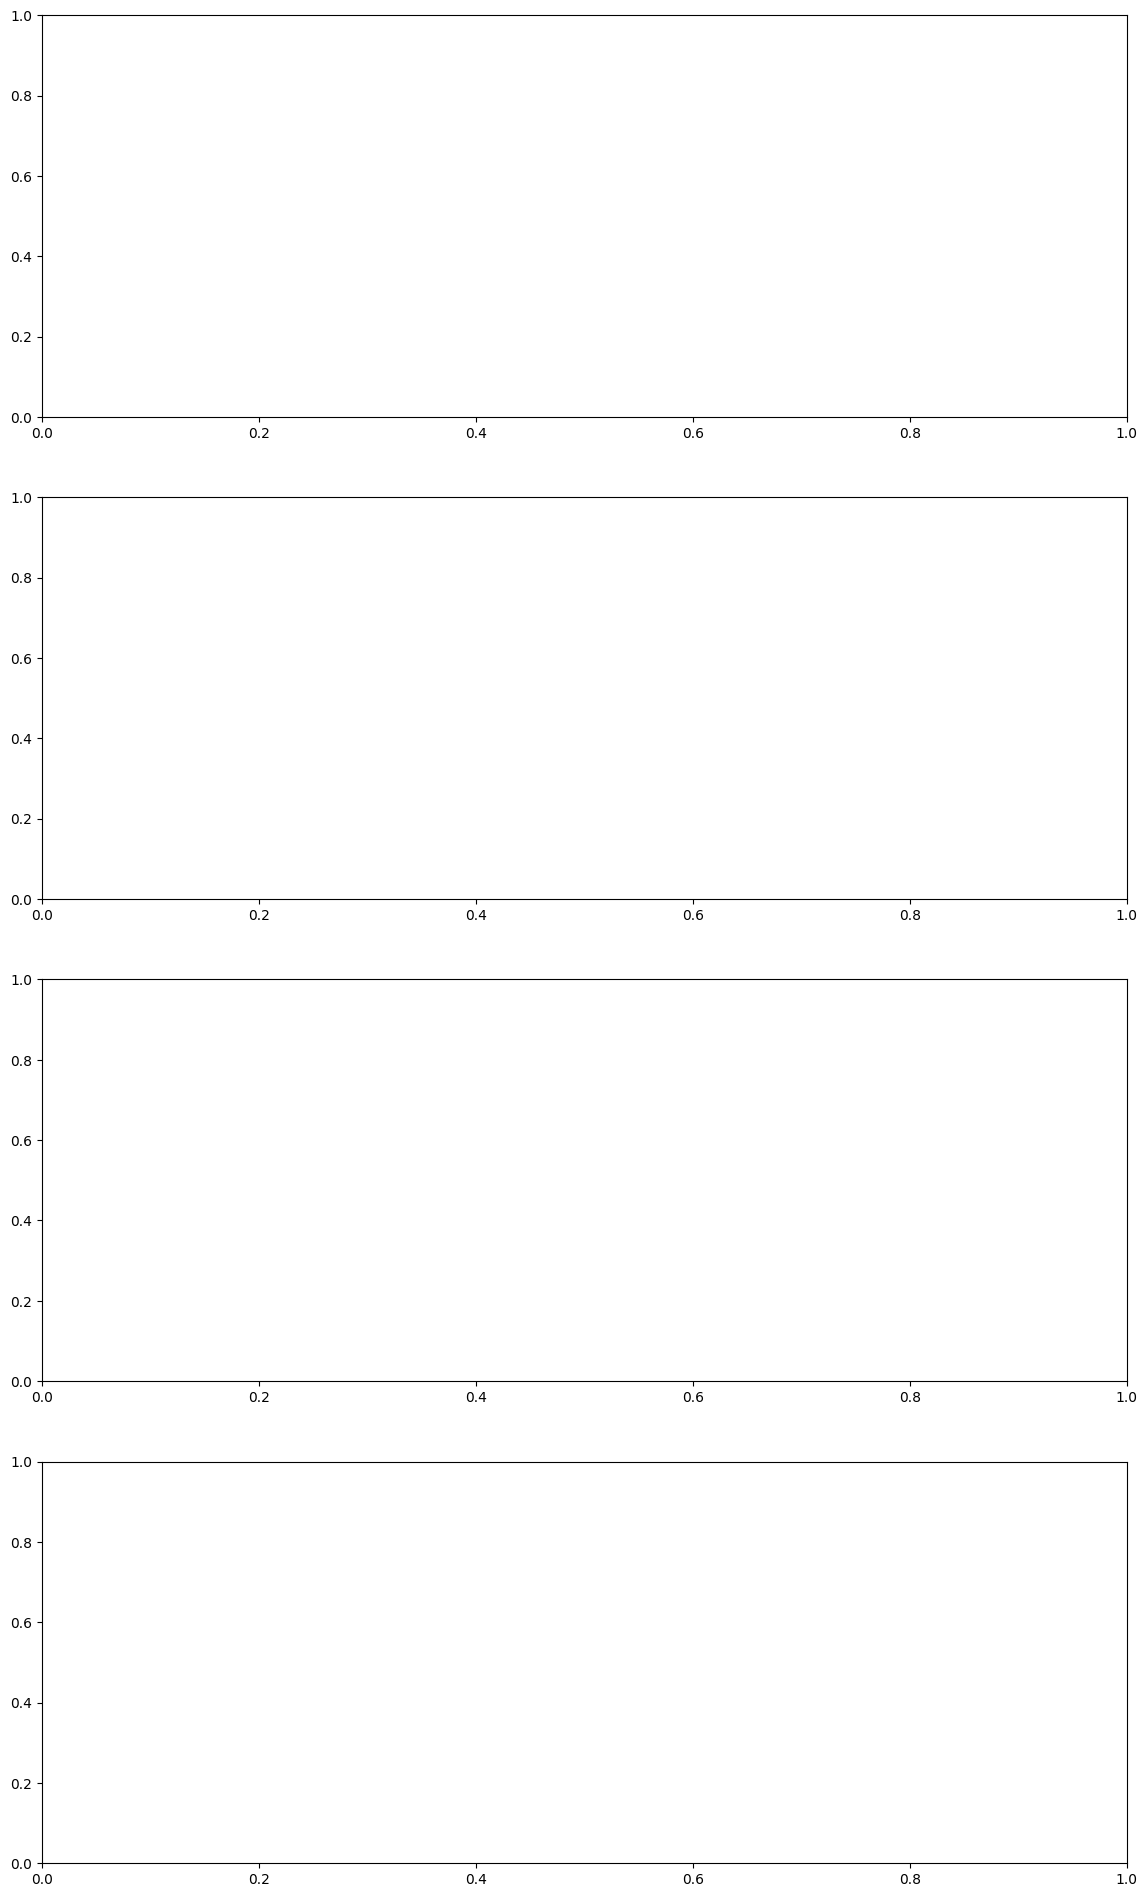

In [18]:
import numpy as np
import matplotlib.pyplot as plt
import cv2
import torch

def visualize_predictions(bench_model, dataset, num_samples=3, confidence_threshold=0.3):
    """Corrected visualization for EfficientDet"""
    bench_model.eval()

    indices = np.random.choice(len(dataset), min(num_samples, len(dataset)), replace=False)

    fig, axes = plt.subplots(num_samples, 1, figsize=(14, 6 * num_samples))
    if num_samples == 1: axes = [axes]

    for idx, sample_idx in enumerate(indices):
        image, target = dataset[sample_idx]
        image_tensor = image.unsqueeze(0).to(device)

        with torch.no_grad():
            # Predict bench returns [xmin, ymin, xmax, ymax, score, class]
            output = bench_model(image_tensor)

        # --- IMAGE FIX ---
        img_np = image.permute(1, 2, 0).cpu().numpy()

        # Check for double-normalization (if max value is very small)
        if img_np.max() < 0.1:
            img_np = img_np * 255.0  # Undo the extra division

        img_np = (img_np * 255).clip(0, 255).astype(np.uint8)
        img_np = np.ascontiguousarray(img_np)

        # --- GROUND TRUTH FIX (Green) ---
        # dataset targets are [ymin, xmin, ymax, xmax]
        for box in target['boxes']:
            ymin, xmin, ymax, xmax = box.cpu().numpy()
            cv2.rectangle(img_np, (int(xmin), int(ymin)), (int(xmax), int(ymax)), (0, 255, 0), 2)
            cv2.putText(img_np, 'GT', (int(xmin), int(ymin)-5),
                       cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 0), 2)

        # --- PREDICTIONS FIX (Red) ---
        # predict_bench output is [xmin, ymin, xmax, ymax, score, class]
        detections = output[0].cpu().numpy()
        num_detections = 0

        for det in detections:
            score = det[4]
            if score >= confidence_threshold:
                xmin, ymin, xmax, ymax = det[0:4]
                cv2.rectangle(img_np, (int(xmin), int(ymin)), (int(xmax), int(ymax)), (255, 0, 0), 2)
                cv2.putText(img_np, f'Pred: {score:.2f}', (int(xmin), int(ymin)-5),
                           cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 0, 0), 2)
                num_detections += 1

        axes[idx].imshow(img_np)
        axes[idx].axis('off')
        axes[idx].set_title(f'Sample {sample_idx} | GT: Green | Pred: Red ({num_detections} found)')

    plt.tight_layout()
    plt.show()

# Run it
visualize_predictions(predict_bench, val_dataset, num_samples=4, confidence_threshold=0.3)

## 12. Test Model on Validation Images

Let's see how well the model performs by visualizing predictions on some validation images.


In [19]:
# Load best model
print("Loading best model for inference...")
checkpoint = torch.load(os.path.join(save_dir, 'best_model.pth'))
model.load_state_dict(checkpoint['model_state_dict'])
model.eval()
print("Model loaded successfully!")


Loading best model for inference...


FileNotFoundError: [Errno 2] No such file or directory: '/content/checkpoints/best_model.pth'

Visualizing predictions on validation images...


/tmp/ipython-input-762523496.py:44: RuntimeWarning: invalid value encountered in cast
  x1, y1, x2, y2 = det[0:4].astype(int)


error: OpenCV(4.12.0) :-1: error: (-5:Bad argument) in function 'rectangle'
> Overload resolution failed:
>  - Can't parse 'pt1'. Sequence item with index 0 has a wrong type
>  - Can't parse 'rec'. Expected sequence length 4, got 2
>  - Can't parse 'pt1'. Sequence item with index 0 has a wrong type
>  - Can't parse 'rec'. Expected sequence length 4, got 2


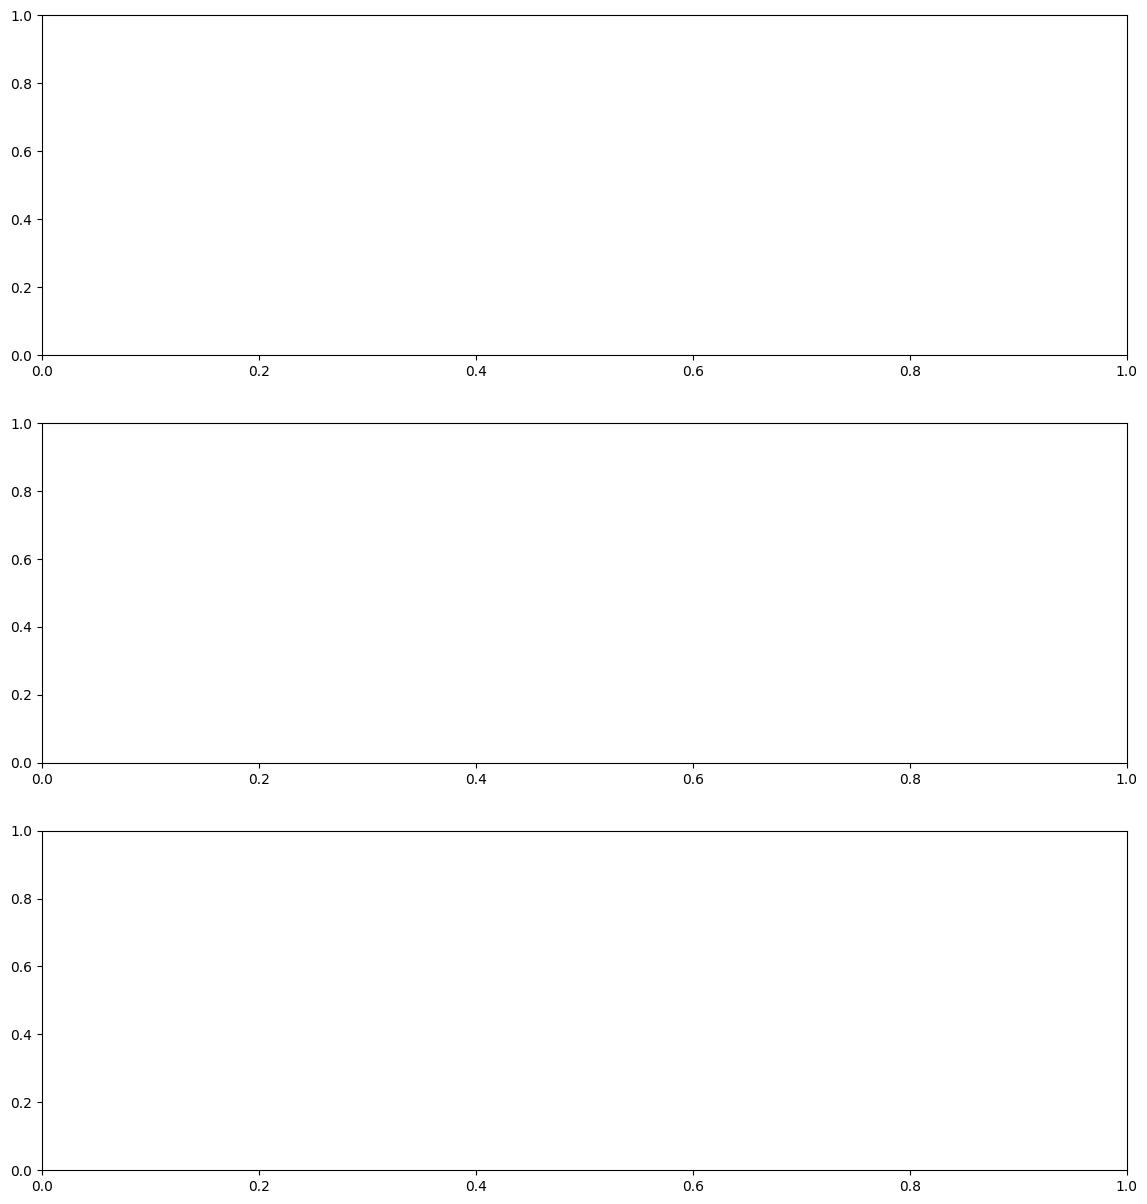

In [21]:
from effdet import DetBenchPredict

def visualize_predictions(model, dataset, num_samples=3, confidence_threshold=0.3):
    """Visualize model predictions on validation images"""
    # 1. Create a Prediction Bench
    # The training bench returns losses; we need the predict bench for boxes
    predictor = DetBenchPredict(model)
    predictor.to(device)
    predictor.eval()

    indices = np.random.choice(len(dataset), min(num_samples, len(dataset)), replace=False)

    fig, axes = plt.subplots(num_samples, 1, figsize=(14, 5 * num_samples))
    if num_samples == 1:
        axes = [axes]

    for idx, sample_idx in enumerate(indices):
        image, target = dataset[sample_idx]
        image_tensor = image.unsqueeze(0).to(device)

        with torch.no_grad():
            # predictor returns a single tensor of shape [1, 100, 6]
            # format: [x1, y1, x2, y2, score, class]
            output = predictor(image_tensor)

        # Convert image to numpy for visualization
        img_np = image.permute(1, 2, 0).cpu().numpy()
        img_np = (img_np * 255).astype(np.uint8).copy() # .copy() ensures it's writeable

        # Draw ground truth boxes (green)
        for box in target['boxes']:
            x1, y1, x2, y2 = box.int().cpu().numpy()
            cv2.rectangle(img_np, (x1, y1), (x2, y2), (0, 255, 0), 2)
            cv2.putText(img_np, 'GT', (x1, y1-5), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 255, 0), 2)

        # Draw predicted boxes (red)
        # Effdet Predict Bench output: [x_min, y_min, x_max, y_max, score, class]
        detections = output[0].cpu().numpy()

        num_detections = 0
        for det in detections:
            score = det[4]
            if score >= confidence_threshold:
                x1, y1, x2, y2 = det[0:4].astype(int)
                cv2.rectangle(img_np, (x1, y1), (x2, y2), (255, 0, 0), 2)
                cv2.putText(img_np, f'Drone {score:.2f}', (x1, y1-5),
                           cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 0, 0), 2)
                num_detections += 1

        axes[idx].imshow(img_np)
        axes[idx].axis('off')
        axes[idx].set_title(f'Sample {sample_idx} - GT: Green ({len(target["boxes"])} boxes), Pred: Red ({num_detections} detections)',
                           fontsize=12, fontweight='bold')

    plt.tight_layout()
    plt.show()

# Run visualization using the underlying model inside the bench
print("Visualizing predictions on validation images...")
visualize_predictions(bench.model, val_dataset, num_samples=3, confidence_threshold=0.3)

## 14. Save Results to Drive


In [ ]:
import zipfile

# Save models
final_path = os.path.join(save_dir, 'efficientdet_drone_final.pth')
torch.save({
    'model_state_dict': model.state_dict(),
    'num_classes': NUM_CLASSES,
    'model_scale': MODEL_SCALE,
    'image_size': IMAGE_SIZE,
    'epoch': checkpoint['epoch'],
    'val_loss': checkpoint['val_loss']
}, final_path)

weights_path = os.path.join(save_dir, 'efficientdet_drone_weights.pth')
torch.save(model.state_dict(), weights_path)

print(f"✓ Models saved locally")

# Copy to Drive
drive_save_path = f'{drive_project_path}/efficientdet_results'
os.makedirs(drive_save_path, exist_ok=True)

shutil.copy2(final_path, f'{drive_save_path}/efficientdet_drone_final.pth')
shutil.copy2(weights_path, f'{drive_save_path}/efficientdet_drone_weights.pth')
shutil.copy2(os.path.join(save_dir, 'best_model.pth'), f'{drive_save_path}/best_model.pth')

# Create zip
zip_path = f'{drive_save_path}/efficientdet_results.zip'
with zipfile.ZipFile(zip_path, 'w', zipfile.ZIP_DEFLATED) as zipf:
    zipf.write(final_path, 'efficientdet_drone_final.pth')
    zipf.write(weights_path, 'efficientdet_drone_weights.pth')
    zipf.write(os.path.join(save_dir, 'best_model.pth'), 'best_model.pth')

print(f"\n✓ Results saved to Google Drive: {drive_save_path}")
print(f"✓ Results zipped: {zip_path}")
print("\n🎉 ALL DONE! Your trained model is saved in Google Drive.")


✓ Models saved locally

✓ Results saved to Google Drive: /content/drive/MyDrive/yolov8_project/efficientdet_results
✓ Results zipped: /content/drive/MyDrive/yolov8_project/efficientdet_results/efficientdet_results.zip

🎉 ALL DONE! Your trained model is saved in Google Drive.


testing with your uploaded image

Saving how-far-fly-drone-768x554.jpg to how-far-fly-drone-768x554.jpg
Processing: how-far-fly-drone-768x554.jpg


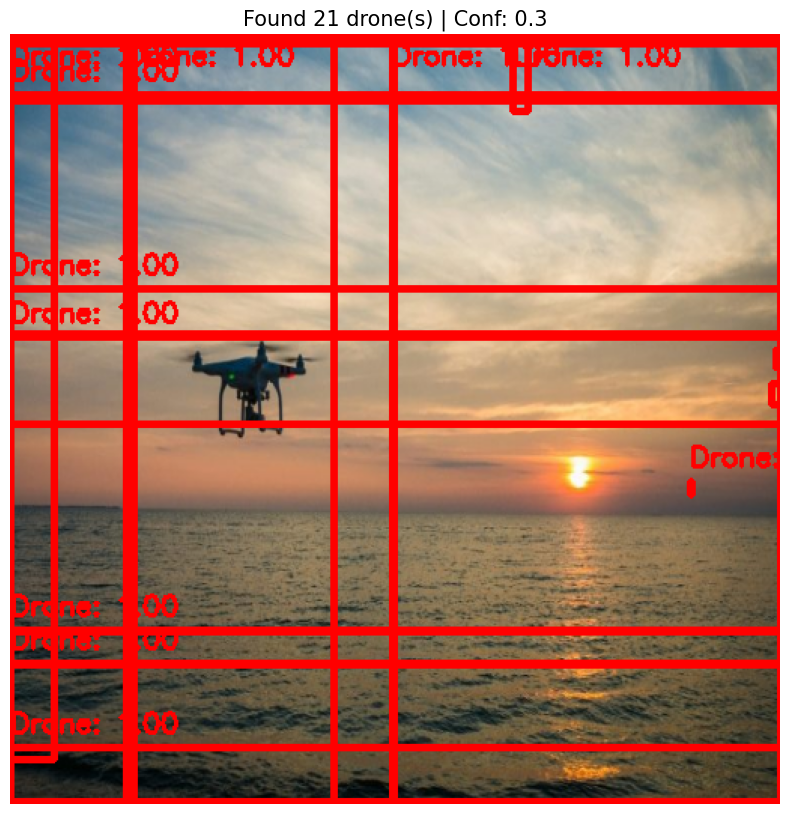

In [22]:
from google.colab import files
import cv2
import torch
import numpy as np
import matplotlib.pyplot as plt

# 1. Upload the image
uploaded = files.upload()

def test_single_image(image_path, model_bench, confidence_threshold=0.3):
    # 2. Load and Preprocess
    orig_image = cv2.imread(image_path)
    if orig_image is None:
        print(f"Could not load image {image_path}")
        return

    orig_image = cv2.cvtColor(orig_image, cv2.COLOR_BGR2RGB)

    # Resize for model (512x512)
    input_image = cv2.resize(orig_image, (IMAGE_SIZE, IMAGE_SIZE))

    # Convert to tensor and normalize (0.0 to 1.0)
    image_tensor = torch.from_numpy(input_image).permute(2, 0, 1).float()
    if image_tensor.max() > 1.0:
        image_tensor = image_tensor / 255.0

    image_tensor = image_tensor.unsqueeze(0).to(device)

    # 3. Inference
    model_bench.eval()
    with torch.no_grad():
        detections = model_bench(image_tensor)

    # 4. Visualization
    display_img = input_image.copy()
    display_img = np.ascontiguousarray(display_img)

    dets = detections[0].cpu().numpy()
    found_count = 0

    for det in dets:
        score = det[4]

        # CRITICAL FIX: Check if coordinates are finite (not infinity or NaN)
        if score >= confidence_threshold and np.isfinite(det[0:4]).all():
            try:
                # Explicitly cast to Python int()
                xmin = int(round(float(det[0])))
                ymin = int(round(float(det[1])))
                xmax = int(round(float(det[2])))
                ymax = int(round(float(det[3])))

                # Clip coordinates to image boundaries
                xmin, xmax = max(0, xmin), min(IMAGE_SIZE, xmax)
                ymin, ymax = max(0, ymin), min(IMAGE_SIZE, ymax)

                # Only draw if the box is valid and has area
                if xmax > xmin and ymax > ymin:
                    cv2.rectangle(display_img, (xmin, ymin), (xmax, ymax), (255, 0, 0), 3)

                    label = f"Drone: {score:.2f}"
                    cv2.putText(display_img, label, (xmin, max(ymin - 10, 20)),
                                cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 0, 0), 2)
                    found_count += 1
            except (OverflowError, ValueError):
                # Extra safety to skip any weird values that slipped through
                continue

    # Show result
    plt.figure(figsize=(10, 10))
    plt.imshow(display_img)
    plt.title(f"Found {found_count} drone(s) | Conf: {confidence_threshold}", fontsize=15)
    plt.axis('off')
    plt.show()

# Run the test
for filename in uploaded.keys():
    print(f"Processing: {filename}")
    test_single_image(filename, predict_bench)